In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.stats.distributions import chi2
from ipywidgets import interact, FloatSlider
from scipy import stats

# **Input**

Import files:
<br>From surfdrive and given student numbers gives us Z_23.3.dat file<br>

In [3]:
filenames = [
    'Z_02.7.dat',
    'Z_07.3.dat',
    'Z_10.6.dat',
    'Z_16.8.dat',
    'Z_23.3.dat',
    'Z_29.7.dat',
    'Z_36.0.dat',
    'Z_42.4.dat',
    'Z_48.8.dat',
    'Z_55.3.dat',
    'Z_61.5.dat',
    'Z_74.4.dat',
    'Z_87.0.dat',
    'Z_94.4.dat']

# Given values based on student ID 
H = 30 # m
U = 1 # m / s
K = 0.41 # von Karman

Make function:
<br>Gives us the height value wrt the bed (using file names)<br>

In [4]:
def get_z(name, h):
    value = float(name.split('_')[1].replace('.dat', ''))
    return value * 0.01 * h

proof of concept

In [5]:
# data4 = np.loadtxt(filenames[4])  # Load the data for 'Z_23.3.dat'

# print(f'{get_z(filenames[4], 100)}% height') 

# tst = data4[:, 0]
# ust = data4[:, 1]
# vst = data4[:, 2]

# ust.mean(), ust.std()
# plt.plot(tst, ust, label='ust')
# plt.plot(tst, np.ones(len(tst)) * ust.mean(), 'r--', label='mean');
# print(f'Mean: {ust.mean():.4f}, Std: {ust.std():.4f}')

# **Result**

In [6]:
zheights = [get_z(item, H) for item in filenames]
avgu = np.zeros(len(filenames))

for item in filenames:
    data = np.loadtxt(item)
    tst = data[:, 0]
    ust = data[:, 1]
    vst = data[:, 2]
    avgu[filenames.index(item)] = ust.mean()

dimavgu = avgu * U

# print(avgu)
# print(zheights)

In [7]:
fitdat = np.polyfit(np.log(zheights)/K, dimavgu, 1)  # Fit a linear model to 1/Klog(z) vs avgu

a = fitdat[0]
print(f'Fitted parameters: {fitdat[0]:.4f}, {fitdat[1]:.4f}')

Fitted parameters: 0.0878, 0.4837


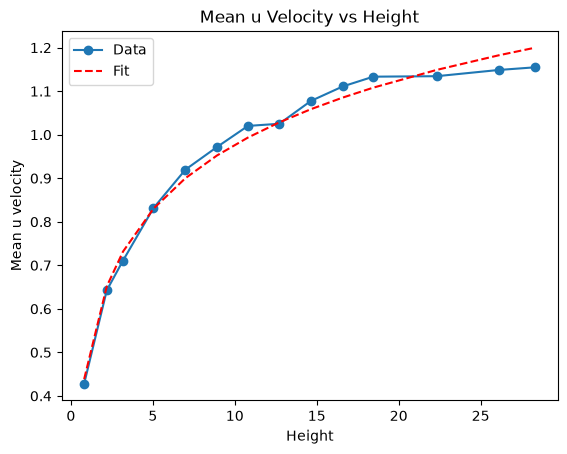

In [8]:
plt.plot(zheights, dimavgu, 'o-', label='Data')
plt.xlabel('Height')
plt.ylabel('Mean u velocity')
plt.title('Mean u Velocity vs Height');
plt.plot(zheights, np.polyval(fitdat, np.log(zheights)/K), 'r--', label='Fit')
plt.legend();

In [9]:
print(f'Log-profile given by a = 1 / K * ln(b)')
print(f'Fitting the formula to the data, we get a = {fitdat[0]:.4f} and b = {fitdat[1]:.4f}')

print(avgu / fitdat[0])

Log-profile given by a = 1 / K * ln(b)
Fitting the formula to the data, we get a = 0.0878 and b = 0.4837
[ 4.87358416  7.31610869  8.09418016  9.46885967 10.47395284 11.06394332
 11.61664473 11.67372875 12.26943724 12.6503278  12.90511599 12.91769296
 13.08029762 13.15004136]
